<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · A level score can still have a winner

Which score should a football query count? A match can be level after 90 minutes, level after extra time, and still have a winner after a penalty shootout. Adding all three score columns double-counts goals and mixes goals with shootout kicks. We will use the 2022 men's World Cup to reconcile the match ledger with individual goal events, classify how matches were decided, and compare the tournament with its knockout rounds.

**Default: recorded actual public data**, not a synthetic fixture. The complete [openfootball 2022 response](https://raw.githubusercontent.com/openfootball/worldcup.json/master/2022/worldcup.json), published under CC0, was captured **2026-11-14 at 10:22:21 UTC**. Replay runs the real tagged worker through VGI against those exact bytes. Live mode fetches that same bounded historical resource afresh and never falls back. Match dates and kickoff strings remain local source labels; the UTC capture clock is a separate fact.

## Choose the match population

`ROUND_SCOPE` is **`"all"`** (default) or **`"knockout"`** (experiment). Knockout means the worker's `group_name IS NULL`, including the third-place match. A winner is therefore not always an advancing team. `DATA_MODE` is **`"replay"`** or **`"live"`**. Both fetch the entire fixed 2022 tournament once; scope is a local filter, not a network-request limit.

Restart Kernel → Run All after editing. Changing the year is outside this recorded example's coverage and is deliberately not a parameter.

In [1]:
ROUND_SCOPE = "all"  # all or knockout; experiment: knockout
DATA_MODE = "replay"  # replay or live; no fallback

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

from recorded_api import RecordedAPI

assert ROUND_SCOPE in {"all", "knockout"}
assert DATA_MODE in {"replay", "live"}
run_utc = datetime.now(UTC).isoformat()
manifest = json.loads(Path("recordings/manifest.json").read_text())
api = RecordedAPI(Path("recordings"), DATA_MODE, Path("artifacts"))
previous_endpoint = os.environ.get("SOCCER_OPENFOOTBALL_URL")
os.environ["SOCCER_OPENFOOTBALL_URL"] = api.url
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"openfootball CC0 · 2022 men's World Cup · {DATA_MODE} · scope: {ROUND_SCOPE} · source receipt shown above",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.91))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-soccer/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-soccer/notebooks/pyproject.toml.

## Materialize the complete tournament through the worker

The literal Git-tagged launch is portable from this notebook directory alone. The supported endpoint override points only openfootball traffic at our exact-path companion; no other provider is queried. Two table functions share the worker's five-minute cache of **one JSON response**. We materialize both before DataFrame conversion so subsequent queries are local.

The match schema defines `team*_goals` as the score after 90 minutes and `team*_extra_time` as the **cumulative** score after extra time. `team*_penalties` contains successful shootout kicks, only when a shootout occurred. NULL means that phase was not recorded; it does not mean zero successful kicks.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'soccer' (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-soccer.git@v0.2.0 --constraints worker-constraints.txt vgi-soccer'
);
CREATE TABLE raw_matches AS SELECT * FROM soccer.world_cup_matches(2022);
CREATE TABLE raw_goals AS SELECT * FROM soccer.world_cup_goals(2022);
CREATE TABLE matches AS
SELECT *, CASE WHEN group_name IS NOT NULL THEN 'Group stage' ELSE round END AS stage,
 CASE WHEN group_name IS NOT NULL THEN 1 WHEN round='Round of 16' THEN 2
      WHEN round='Quarter-finals' THEN 3 WHEN round='Semi-finals' THEN 4
      WHEN round='Match for third place' THEN 5 WHEN round='Final' THEN 6 ELSE 7 END AS stage_order,
 coalesce(team1_extra_time,team1_goals) AS played1,
 coalesce(team2_extra_time,team2_goals) AS played2,
 team1_goals+team2_goals AS goals90,
 coalesce(team1_extra_time+team2_extra_time-team1_goals-team2_goals,0) AS additional_extra_goals,
 CASE WHEN team1_penalties IS NOT NULL THEN 'Shootout'
      WHEN team1_extra_time IS NOT NULL THEN 'Extra time'
      WHEN winner IS NULL THEN 'Draw after 90'
      ELSE 'Decided in 90' END AS resolution
FROM raw_matches;
CREATE TABLE selected AS SELECT * FROM matches
WHERE '{{ROUND_SCOPE}}'='all' OR group_name IS NULL;

,Count


In [4]:
audit = json.loads(Path("artifacts/request-audit.json").read_text())
assert len(audit) == 1 and audit[0]["status"] == 200
payload = json.loads(Path("artifacts/worldcup-2022.json").read_text())
all_matches = con.execute("SELECT * FROM raw_matches ORDER BY match_number").df()
fingerprint = hashlib.sha256(all_matches.to_json(orient="records", date_format="iso").encode()).hexdigest()
assert len(all_matches) == len(payload["matches"])
assert not all_matches.match_number.duplicated().any()
source_time = manifest["received_utc"] if DATA_MODE == "replay" else audit[0]["received_utc"]
prose(
    f"**{len(all_matches)} matches** were materialized from **one {audit[0]['bytes']:,}-byte response**, received at `{source_time}`. Run clock: `{run_utc}`. Response SHA256: `{audit[0]['sha256']}`. Normalized match fingerprint: `{fingerprint}`. Replay receipt in the HTTP audit is the local replay time; the source capture time above remains unchanged."
)

**64 matches** were materialized from **one 25,358-byte response**, received at `2026-11-14T10:22:21.420017+00:00`. Run clock: `2026-11-14T10:26:19.166645+00:00`. Response SHA256: `f4f0499c30076bc8e3702f400765900797fb22212a32aaa8137e1dfc49449a68`. Normalized match fingerprint: `ced745626bfc01dbc558e656c4e990fd9e56b2c686201a151707a296986d9930`. Replay receipt in the HTTP audit is the local replay time; the source capture time above remains unchanged.

## Check the goal ledger before counting outcomes

Join on the worker's tournament match number and the credited team, not player names. A penalty scored during play is a goal. An own goal is credited to the benefiting team; it remains in the team total even though a scorer leaderboard would exclude it. Shootout kicks do not appear in this goal-event table.

For every match, the goal-event count should equal the cumulative score after play. We also reconstruct the winning team from shootout, extra-time, then 90-minute scores and compare it with the worker's `winner`. These checks distinguish a valid 0–0 from an incomplete ledger and fail visibly if a live source revision breaks the relationships.

In [5]:
%%sql goal_checks <<
WITH ledger AS (
 SELECT m.match_number,count(g.match_number) AS goal_events,
 count(g.match_number) FILTER(WHERE g.team=m.team1) AS team1_events,
 count(g.match_number) FILTER(WHERE g.team=m.team2) AS team2_events
 FROM matches m LEFT JOIN raw_goals g USING(match_number) GROUP BY m.match_number
), checked AS (
 SELECT m.*,l.* EXCLUDE(match_number),
 CASE WHEN coalesce(team1_penalties,team1_extra_time,team1_goals)>
                coalesce(team2_penalties,team2_extra_time,team2_goals) THEN team1
      WHEN coalesce(team1_penalties,team1_extra_time,team1_goals)<
                coalesce(team2_penalties,team2_extra_time,team2_goals) THEN team2 END AS expected_winner
 FROM matches m JOIN ledger l USING(match_number)
)
SELECT count(*) AS checked_matches,
 count(*) FILTER(WHERE team1_events<>played1 OR team2_events<>played2) AS ledger_mismatches,
 count(*) FILTER(WHERE winner IS DISTINCT FROM expected_winner) AS winner_mismatches,
 count(*) FILTER(WHERE additional_extra_goals<0) AS negative_extra_increments,
 count(*) FILTER(WHERE (team1_extra_time IS NULL)<>(team2_extra_time IS NULL)
 OR (team1_penalties IS NULL)<>(team2_penalties IS NULL)) AS incomplete_score_pairs,
 count(*) FILTER(WHERE team1_goals IS NULL OR team2_goals IS NULL) AS unknown_90_scores,
 count(*) FILTER(WHERE team1_penalties IS NOT NULL AND (played1<>played2 OR team1_penalties=team2_penalties)) AS invalid_shootouts,
 count(*) FILTER(WHERE group_name IS NULL AND winner IS NULL) AS unresolved_knockouts
FROM checked;

In [6]:
display(goal_checks)
assert con.execute("SELECT count(*) FROM matches WHERE stage_order=7").fetchone()[0] == 0
assert goal_checks.checked_matches.iloc[0] == len(all_matches)
assert goal_checks.iloc[0, 1:].eq(0).all()
assert (
    con.execute(
        "SELECT count(*) FROM raw_goals g LEFT JOIN matches m USING(match_number) WHERE m.match_number IS NULL OR g.team NOT IN (m.team1,m.team2) OR g.opponent NOT IN (m.team1,m.team2) OR g.team=g.opponent"
    ).fetchone()[0]
    == 0
)
prose(
    f"All **{goal_checks.checked_matches.iloc[0]} match ledgers** reconcile with the worker's goal events; the winner reconstruction agrees and no knockout result is unresolved. These checks validate consistency of this response and mapping, not the historical accuracy of every upstream event."
)

,checked_matches,ledger_mismatches,winner_mismatches,negative_extra_increments,incomplete_score_pairs,unknown_90_scores,invalid_shootouts,unresolved_knockouts
0,64,0,0,0,0,0,0,0


All **64 match ledgers** reconcile with the worker's goal events; the winner reconstruction agrees and no knockout result is unresolved. These checks validate consistency of this response and mapping, not the historical accuracy of every upstream event.

## How were the selected matches decided?

Classify each match exactly once. The categories describe the recorded deciding phase, not the number of goals or a team's strength. Group-stage draws have no winner; a shootout-decided knockout can still be level after all goals during play. Keep the group stage aggregated so the comparison uses tournament phases rather than mixing individual groups with knockout rounds.

In [7]:
%%sql stages <<
SELECT stage,min(stage_order) AS stage_order,count(*) AS matches,
 count(*) FILTER(WHERE resolution='Decided in 90') AS decided90,
 count(*) FILTER(WHERE resolution='Draw after 90') AS draws90,
 count(*) FILTER(WHERE resolution='Extra time') AS extra_time,
 count(*) FILTER(WHERE resolution='Shootout') AS shootouts,
 sum(goals90)::BIGINT AS goals90,sum(additional_extra_goals)::BIGINT AS extra_goals,
 sum(played1+played2)::BIGINT AS goals_during_play,
 sum(coalesce(team1_penalties+team2_penalties,0))::BIGINT AS successful_shootout_kicks
FROM selected GROUP BY stage ORDER BY stage_order;

,stage,stage_order,matches,decided90,draws90,extra_time,shootouts,goals90,extra_goals,goals_during_play,successful_shootout_kicks
0,Group stage,1,48,38,10,0,0,120,0,120,0
1,Round of 16,2,8,6,0,0,2,28,0,28,7
2,Quarter-finals,3,4,2,0,0,2,8,2,10,13
3,Semi-finals,4,2,2,0,0,0,5,0,5,0
4,Match for third place,5,1,1,0,0,0,3,0,3,0
5,Final,6,1,0,0,0,1,4,2,6,6


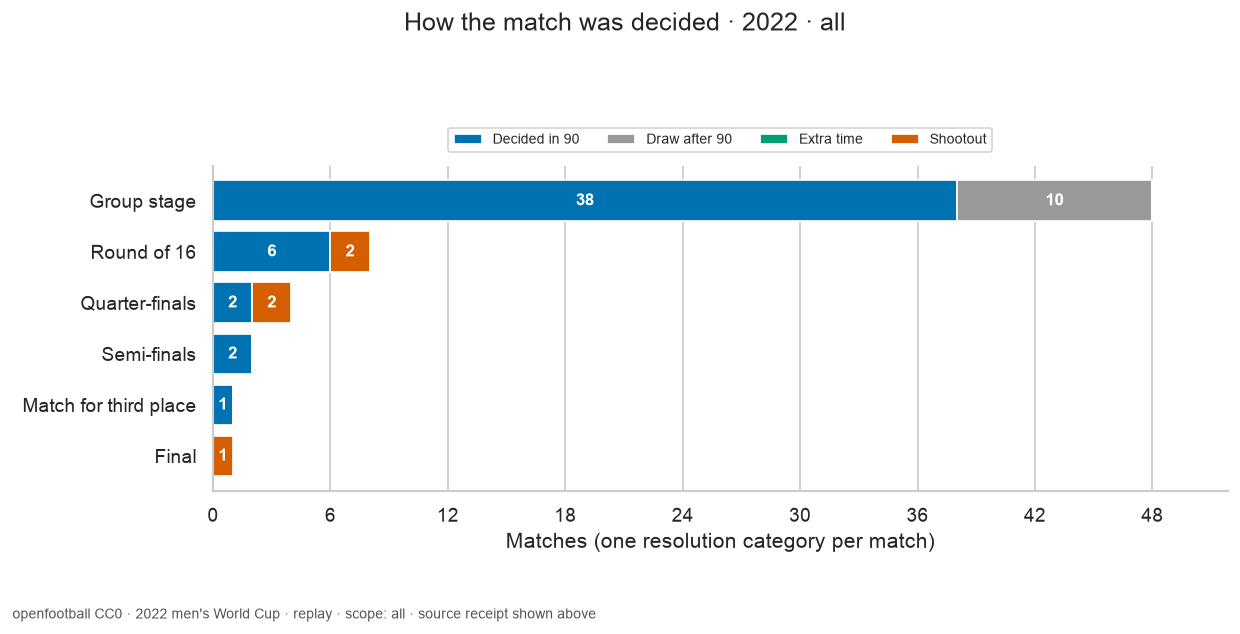

The **all** population contains **64 matches**: **49 decided in 90 minutes**, **10 draws after 90**, **0 decided in extra time**, and **5 decided by shootout**. These counts use the result phases, not the winner column alone; dropping NULL winners would silently remove valid group-stage draws.

In [8]:
display(stages)
assert (stages[["decided90", "draws90", "extra_time", "shootouts"]].sum(axis=1) == stages.matches).all()
assert (stages.goals90 + stages.extra_goals == stages.goals_during_play).all()
fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(stages))
for key, label, color in [
    ("decided90", "Decided in 90", "#0072b2"),
    ("draws90", "Draw after 90", "#999999"),
    ("extra_time", "Extra time", "#009e73"),
    ("shootouts", "Shootout", "#d55e00"),
]:
    values = stages[key].to_numpy()
    ax.barh(stages.stage, values, left=left, label=label, color=color)
    for i, (v, start) in enumerate(zip(values, left, strict=True)):
        if v:
            ax.text(
                start + v / 2,
                i,
                str(v),
                ha="center",
                va="center",
                color="white",
                fontsize=10,
                fontweight="bold",
            )
    left += values
ax.invert_yaxis()
ax.set(xlabel="Matches (one resolution category per match)", xlim=(0, max(stages.matches) * 1.08))
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=8)
fig.suptitle(f"How the match was decided · 2022 · {ROUND_SCOPE}")
finish(fig)
prose(
    f"The **{ROUND_SCOPE}** population contains **{stages.matches.sum()} matches**: **{stages.decided90.sum()} decided in 90 minutes**, **{stages.draws90.sum()} draws after 90**, **{stages.extra_time.sum()} decided in extra time**, and **{stages.shootouts.sum()} decided by shootout**. These counts use the result phases, not the winner column alone; dropping NULL winners would silently remove valid group-stage draws."
)

## Keep goals and shootout kicks in separate ledgers

The first panel adds 90-minute goals to **additional** extra-time goals. It never adds the cumulative extra-time score a second time. The second panel counts successful shootout kicks; their bars are separate because those kicks are not match goals. Each panel uses its own labeled scale. A zero extra-time increment can coexist with extra time being played, and a zero shootout-kick total for a phase usually means no shootout occurred, not a failed measurement.

In [9]:
%%sql detail <<
SELECT match_number,round,team1,team2,team1_goals,team2_goals,
 team1_extra_time,team2_extra_time,team1_penalties,team2_penalties,
 played1+played2 AS goal_events_expected,winner
FROM selected WHERE team1_extra_time IS NOT NULL OR team1_penalties IS NOT NULL
ORDER BY match_number;

,match_number,round,team1,team2,team1_goals,team2_goals,team1_extra_time,team2_extra_time,team1_penalties,team2_penalties,goal_events_expected,winner
0,53,Round of 16,Japan,Croatia,1,1,1,1,1,3,2,Croatia
1,55,Round of 16,Morocco,Spain,0,0,0,0,3,0,0,Morocco
2,57,Quarter-finals,Croatia,Brazil,0,0,1,1,4,2,2,Croatia
3,58,Quarter-finals,Netherlands,Argentina,2,2,2,2,3,4,4,Argentina
4,64,Final,Argentina,France,2,2,3,3,4,2,6,Argentina


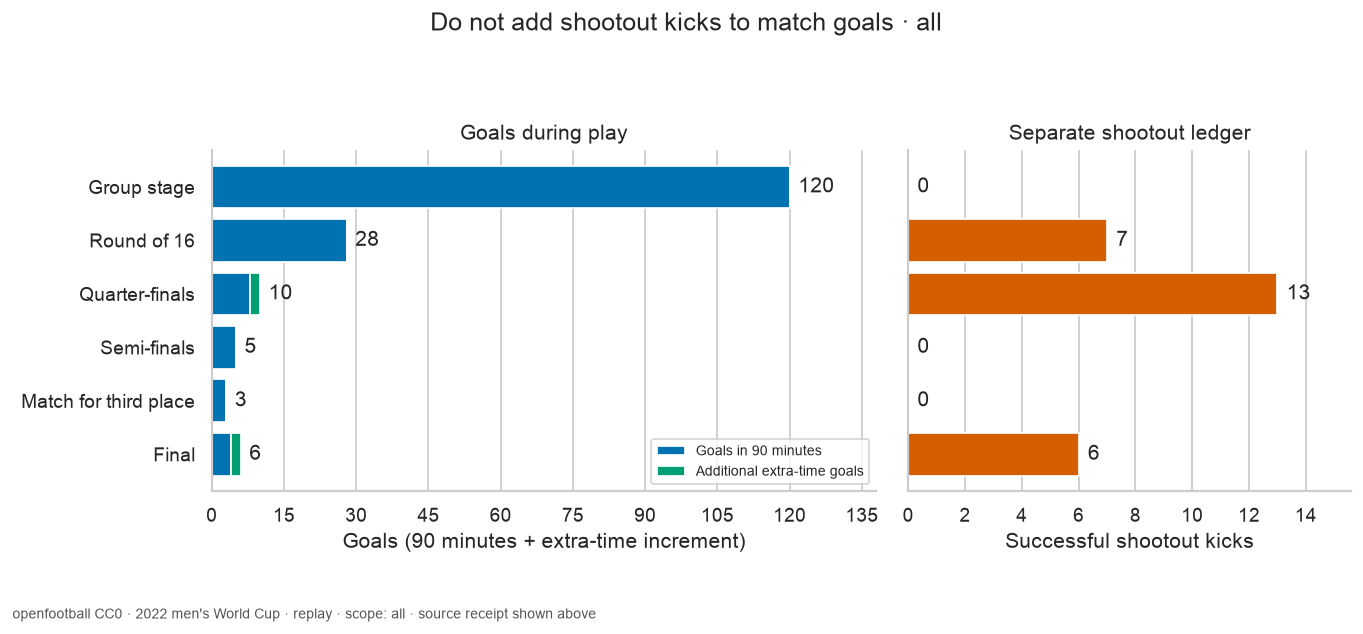

Selected matches contain **172 goals during play**: **168 by 90 minutes** plus **4 added in extra time**. The **26 successful shootout kicks** belong in a different ledger. The detailed table preserves NULL phases and true zero scores, so a reader can audit that distinction match by match. Player-name spelling is not normalized here; these team totals should not be repurposed as a scorer ranking without identity work.

4256

In [10]:
display(detail)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].barh(stages.stage, stages.goals90, label="Goals in 90 minutes", color="#0072b2")
axes[0].barh(
    stages.stage,
    stages.extra_goals,
    left=stages.goals90,
    label="Additional extra-time goals",
    color="#009e73",
)
axes[1].barh(stages.stage, stages.successful_shootout_kicks, color="#d55e00")
for i, row in enumerate(stages.itertuples()):
    axes[0].text(
        row.goals_during_play + max(stages.goals_during_play) * 0.015,
        i,
        str(row.goals_during_play),
        va="center",
    )
    axes[1].text(
        row.successful_shootout_kicks + max(1, max(stages.successful_shootout_kicks)) * 0.025,
        i,
        str(row.successful_shootout_kicks),
        va="center",
    )
axes[0].invert_yaxis()
axes[0].set(
    title="Goals during play",
    xlabel="Goals (90 minutes + extra-time increment)",
    xlim=(0, max(stages.goals_during_play) * 1.15),
)
axes[1].set(
    title="Separate shootout ledger",
    xlabel="Successful shootout kicks",
    xlim=(0, max(1, max(stages.successful_shootout_kicks)) * 1.2),
)
axes[0].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle(f"Do not add shootout kicks to match goals · {ROUND_SCOPE}")
finish(fig)
prose(
    f"Selected matches contain **{stages.goals_during_play.sum()} goals during play**: **{stages.goals90.sum()} by 90 minutes** plus **{stages.extra_goals.sum()} added in extra time**. The **{stages.successful_shootout_kicks.sum()} successful shootout kicks** belong in a different ledger. The detailed table preserves NULL phases and true zero scores, so a reader can audit that distinction match by match. Player-name spelling is not normalized here; these team totals should not be repurposed as a scorer ranking without identity work."
)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "round_scope": ROUND_SCOPE,
            "mode": DATA_MODE,
            "run_utc": run_utc,
            "fingerprint": fingerprint,
            "stages": stages.to_dict(orient="records"),
            "detail": json.loads(detail.to_json(orient="records")),
            "checks": goal_checks.to_dict(orient="records"),
            "requests": audit,
        },
        indent=2,
    )
)

## Experiment: remove the group stage

Change only `ROUND_SCOPE` from **`"all"` to `"knockout"`**, keeping replay mode. Predict that the group-stage bar and its goals disappear while every knockout bar, shootout detail row and winner stays the same. Compare the population counts, both goal ledgers, response SHA256 and normalized match fingerprint. The full-source checks and **one-request budget** must still pass: a local scope change does not fetch a different dataset. Restore **`"all"`** afterwards.

This describes one completed tournament, not a prediction of team quality, a model of future scores, or evidence about shootout skill. The separate ledgers make the descriptive result interpretable without treating every numeric score as the same quantity.

In [11]:
con.close()
api.close()
if previous_endpoint is None:
    os.environ.pop("SOCCER_OPENFOOTBALL_URL", None)
else:
    os.environ["SOCCER_OPENFOOTBALL_URL"] = previous_endpoint

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)